In [36]:
from datasets import load_dataset

# Load the hindi subset of the dataset
dataset = load_dataset("ai4bharat/IndicCorpV2", "indiccorp_v2", split="hin_Deva",streaming=True)


In [37]:
dataset

IterableDataset({
    features: Unknown,
    num_shards: 3
})

In [38]:
for example in dataset.take(3):
    print(example)
    print("-" * 100)

{'text': 'लोगों को बिलों संबंधी सुविधा देना ही उनका काम'}
----------------------------------------------------------------------------------------------------
{'text': ''}
----------------------------------------------------------------------------------------------------
{'text': 'इनेलो 1987 में उस वक्त ऐसे ही दोराहे पर खड़ी थी, जब पूर्व उपप्रधानमंत्री देवीलाल ने अपने पुत्र ओमप्रकाश चौटाला को अपना राजनीतिक उत्तराधिकारी घोषित किया था। हालांकि तब पार्टी पर देवीलाल की मजबूत पकड़ के चलते पार्टी टूटने से बच गई थी। 1989 में देवीलाल केन्द्र की राजनीति में सक्रिय हो गए थे और उनके उपप्रधानमंत्री बनने के पश्चात् उनके तीन बेटों जगदीश सिंह, रणजीत सिंह और ओमप्रकाश चौटाला में से रणजीत और ओमप्रकाश के बीच हरियाणा में उनकी राजनीतिक विरासत को लेकर जंग शुरू हो गई थी। उन परिस्थितियों में देवीलाल ने कड़ा निर्णय लेते हुए पार्टी की बागडोर ओमप्रकाश चौटाला के हवाले कर दी थी, जिसके बाद रणजीत की बगावत का असर पार्टी, संगठन और उनकी सरकार पर भी पड़ा था। उस समय रणजीत की नाराजगी के चलते उनके समर्थन में कई कैबिनेट मं

In [39]:
import re

def sentence_tokenize_hindi(paragraph):

    if not isinstance(paragraph, str):
        return []

    paragraph = paragraph.strip()

    # Split after Hindi full stop, question mark,
    # or exclamation mark
    sentences = re.split(
        r'(?<=[।?!])\s+',
        paragraph
    )

    # Remove empty and extremely short sentences
    sentences = [
        sentence.strip()
        for sentence in sentences
        if len(sentence.strip()) > 1
    ]

    return sentences

In [40]:
paragraph = """
भारत एक विशाल देश है। इसकी कई भाषाएँ और संस्कृतियाँ हैं।
दिल्ली भारत की राजधानी है!
क्या आप भारत गए हैं?
"""

print(sentence_tokenize_hindi(paragraph))

['भारत एक विशाल देश है।', 'इसकी कई भाषाएँ और संस्कृतियाँ हैं।', 'दिल्ली भारत की राजधानी है!', 'क्या आप भारत गए हैं?']


In [41]:
from tqdm import tqdm

TARGET_SENTENCES = 1_025_000

sentences = []

for example in tqdm(dataset):

    paragraph = example["text"]

    paragraph_sentences = sentence_tokenize_hindi(
        paragraph
    )

    for sentence in paragraph_sentences:

        # Remove extremely short sentences
        if len(sentence.split()) >= 3:
            sentences.append(sentence)

    if len(sentences) >= TARGET_SENTENCES:
        break

734026it [00:28, 25918.84it/s]


In [42]:
print("Total sentences collected:", len(sentences))

Total sentences collected: 1025001


In [43]:
import pandas as pd

sentences_df = pd.DataFrame({
    "sentence": sentences
})

sentences_df.to_csv(
    "hindi_sentences.csv",
    index=False,
    encoding="utf-8"
)

In [44]:
sentences_df["length"] = (
    sentences_df["sentence"]
    .apply(lambda x: len(x.split()))
)

print(
    sentences_df["length"].describe()
)

count    1.025001e+06
mean     2.061036e+01
std      2.155370e+01
min      3.000000e+00
25%      1.100000e+01
50%      1.600000e+01
75%      2.400000e+01
max      3.276000e+03
Name: length, dtype: float64


In [45]:
sentences[0]

'लोगों को बिलों संबंधी सुविधा देना ही उनका काम'

In [46]:
def get_length_bucket(length):

    if length <= 5:
        return "1-5"

    elif length <= 10:
        return "6-10"

    elif length <= 20:
        return "11-20"

    elif length <= 30:
        return "21-30"

    elif length <= 50:
        return "31-50"

    else:
        return "50+"

In [47]:
sentences_df["length_bucket"] = (
    sentences_df["length"]
    .apply(get_length_bucket)
)

In [48]:
print(
    sentences_df["length_bucket"]
    .value_counts()
)

length_bucket
11-20    446204
21-30    203405
6-10     193539
31-50    100312
50+       44733
1-5       36808
Name: count, dtype: int64


In [49]:
import numpy as np

def stratified_length_split(
    df,
    dev_size=1000,
    test_size=1000,
    random_state=42
):

    np.random.seed(random_state)

    dev_parts = []
    test_parts = []

    # Distribution of sentence lengths
    bucket_counts = (
        df["length_bucket"]
        .value_counts()
    )

    total_samples = len(df)

    for bucket, count in bucket_counts.items():

        bucket_df = df[
            df["length_bucket"] == bucket
        ].sample(
            frac=1,
            random_state=random_state
        )

        # Number proportional to bucket size
        dev_n = round(
            (count / total_samples) *
            dev_size
        )

        test_n = round(
            (count / total_samples) *
            test_size
        )

        # Ensure enough samples remain
        selected_n = dev_n + test_n

        selected = bucket_df.iloc[
            :selected_n
        ]

        dev_parts.append(
            selected.iloc[:dev_n]
        )

        test_parts.append(
            selected.iloc[
                dev_n:dev_n + test_n
            ]
        )

    dev_df = pd.concat(
        dev_parts,
        ignore_index=True
    )

    test_df = pd.concat(
        test_parts,
        ignore_index=True
    )

    return dev_df, test_df

In [50]:
import numpy as np
import pandas as pd


def stratified_length_split(
    df,
    dev_size=1000,
    test_size=1000,
    random_state=42
):

    dev_parts = []
    test_parts = []

    # Distribution of sentence length buckets
    bucket_counts = (
        df["length_bucket"]
        .value_counts()
    )

    total_samples = len(df)

    for i, (bucket, count) in enumerate(
        bucket_counts.items()
    ):

        # Get all sentences belonging to this bucket
        bucket_df = df[
            df["length_bucket"] == bucket
        ].sample(
            frac=1,
            random_state=random_state + i
        )

        # Number of development samples
        dev_n = round(
            (count / total_samples) *
            dev_size
        )

        # Number of test samples
        test_n = round(
            (count / total_samples) *
            test_size
        )

        # Development samples
        dev_part = bucket_df.iloc[
            :dev_n
        ]

        # Test samples
        test_part = bucket_df.iloc[
            dev_n:dev_n + test_n
        ]

        dev_parts.append(dev_part)

        test_parts.append(test_part)


    # Combine all buckets
    dev_df = pd.concat(
        dev_parts
    )

    test_df = pd.concat(
        test_parts
    )

    # If rounding causes slightly more/fewer than 1000,
    # adjust to exactly 1000
    dev_df = dev_df.sample(
        n=dev_size,
        random_state=random_state
    )

    test_df = test_df.sample(
        n=test_size,
        random_state=random_state
    )

    # Training data = everything except dev and test
    train_df = df.drop(
        dev_df.index.union(test_df.index)
    )

    return train_df, dev_df, test_df

In [51]:
train_df, dev_df, test_df = stratified_length_split(
    sentences_df,
    dev_size=1000,
    test_size=1000,
    random_state=42
)

In [52]:
print("Training samples   :", len(train_df))
print("Development samples:", len(dev_df))
print("Test samples       :", len(test_df))

Training samples   : 1023001
Development samples: 1000
Test samples       : 1000


In [53]:
distribution_comparison = pd.DataFrame({

    "Original (%)":
    sentences_df["length_bucket"]
    .value_counts(normalize=True)
    .sort_index()
    * 100,

    "Development (%)":
    dev_df["length_bucket"]
    .value_counts(normalize=True)
    .sort_index()
    * 100,

    "Test (%)":
    test_df["length_bucket"]
    .value_counts(normalize=True)
    .sort_index()
    * 100

}).fillna(0)

print(
    distribution_comparison.round(2)
)

               Original (%)  Development (%)  Test (%)
length_bucket                                         
1-5                    3.59              3.6       3.6
11-20                 43.53             43.5      43.5
21-30                 19.84             19.8      19.8
31-50                  9.79              9.8       9.8
50+                    4.36              4.4       4.4
6-10                  18.88             18.9      18.9


In [54]:
def get_length_bucket(length):

    if length <= 10:
        return "1-10"
    elif length <= 20:
        return "11-20"
    elif length <= 30:
        return "21-30"
    elif length <= 50:
        return "31-50"
    elif length <= 75:
        return "51-75"
    elif length <= 100:
        return "76-100"
    elif length <= 150:
        return "101-150"
    elif length <= 200:
        return "151-200"
    else:
        return "200+"

In [55]:
sentences_df["length_bucket"] = sentences_df["length"].apply(get_length_bucket)

train_df, dev_df, test_df = stratified_length_split(
    sentences_df,
    dev_size=1000,
    test_size=1000,
    random_state=42
)

In [56]:
print("Total training sentences:", len(train_df))
print("Development sentences:", len(dev_df))
print("Test sentences:", len(test_df))

Total training sentences: 1023001
Development sentences: 1000
Test sentences: 1000


In [57]:
train_df = train_df.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

print(train_df.head())

                                            sentence  length length_bucket
0  इस कॉन्फ्रेंस में हमारे द्वारा आगामी सीजन हेतु...      38         31-50
1  वैक्सीन की दोनों डोज लगवा चुके लोग दोबारा पॉजि...      31         31-50
2  वहीं पूरे देश की बात करें तो पिछले 24 घंटों मे...      34         31-50
3  मामला जनपद पंचायत किरनापुर की कटंगी पंचायत का है।       9          1-10
4                                  इंतजामिया पर आरोप       3          1-10


In [58]:
TRAIN_SIZES = [
    100_000,
    300_000,
    500_000,
    1_000_000
]

In [59]:
train_subsets = {}

for size in TRAIN_SIZES:

    if len(train_df) >= size:

        train_subsets[size] = train_df.iloc[:size].copy()

        print(
            f"{size:,} samples created"
        )

    else:

        print(
            f"Not enough training samples for {size:,}"
        )

100,000 samples created
300,000 samples created
500,000 samples created
1,000,000 samples created


In [60]:
VOCAB_SIZES = [
    20_000,
    30_000,
    50_000
]

In [61]:
train_text_100k = train_subsets[100_000]["sentence"].tolist()

print(len(train_text_100k))
print(train_text_100k[0])

100000
इस कॉन्फ्रेंस में हमारे द्वारा आगामी सीजन हेतु अनेक डवलपमेण्ट किए गये हैं, जिनमें फैन्सी सूटिंग, जैकार्ड, टीआर फैब्रिक में अनेक कलर रेंज में काफी सारे कलेक्शन प्रमुख हैं, जिन्हें फैब्रिक डिस्प्ले के माध्यम से पेश किया जाएगा।


In [62]:
from collections import Counter

def get_word_frequencies(texts):

    word_freq = Counter()

    for sentence in texts:
        words = sentence.split()

        for word in words:
            word_freq[word] += 1

    return word_freq

In [63]:
def initialize_bpe_vocab(word_freq):

    vocab = {}

    for word, freq in word_freq.items():

        tokens = tuple(list(word) + ["</w>"])

        vocab[tokens] = freq

    return vocab

def get_pair_counts(vocab):

    pairs = Counter()

    for tokens, freq in vocab.items():

        for i in range(len(tokens) - 1):

            pair = (
                tokens[i],
                tokens[i + 1]
            )

            pairs[pair] += freq

    return pairs

def merge_pair(pair, vocab):

    new_vocab = {}

    merged_token = "".join(pair)

    for tokens, freq in vocab.items():

        new_tokens = []
        i = 0

        while i < len(tokens):

            if (
                i < len(tokens) - 1
                and tokens[i] == pair[0]
                and tokens[i + 1] == pair[1]
            ):

                new_tokens.append(merged_token)
                i += 2

            else:

                new_tokens.append(tokens[i])
                i += 1

        new_vocab[tuple(new_tokens)] = freq

    return new_vocab



In [64]:
!pip install -q tokenizers

In [65]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

In [66]:
def train_bpe(texts, vocab_size):

    tokenizer = Tokenizer(
        models.BPE(
            unk_token="[UNK]"
        )
    )

    tokenizer.pre_tokenizer = (
        pre_tokenizers.Whitespace()
    )

    trainer = trainers.BpeTrainer(
        vocab_size=vocab_size,
        special_tokens=["[UNK]"]
    )

    tokenizer.train_from_iterator(
        texts,
        trainer=trainer
    )

    return tokenizer

In [67]:
bpe_100k_20k = train_bpe(
    train_subsets[100_000]["sentence"].tolist(),
    vocab_size=20_000
)

In [68]:
print(
    "Vocabulary size:",
    bpe_100k_20k.get_vocab_size()
)

Vocabulary size: 20000


In [69]:
sample = dev_df["sentence"].iloc[0]

tokens = bpe_100k_20k.encode(sample).tokens

print("Sentence:")
print(sample)

print("\nBPE tokens:")
print(tokens)

print("\nNumber of tokens:")
print(len(tokens))

Sentence:
वहां पर भाजपा प्रमुख जेपी नड्डा भी मौजूद थे।

BPE tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']

Number of tokens:
10


In [72]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers


def train_wordpiece(texts, vocab_size):
    """
    Train a WordPiece tokenizer.

    Parameters:
        texts: list of training sentences
        vocab_size: desired vocabulary size

    Returns:
        trained WordPiece tokenizer
    """

    tokenizer = Tokenizer(
        models.WordPiece(
            unk_token="[UNK]"
        )
    )

    # Split input into words before applying WordPiece
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

    trainer = trainers.WordPieceTrainer(
        vocab_size=vocab_size,
        special_tokens=["[UNK]"]
    )

    tokenizer.train_from_iterator(
        texts,
        trainer=trainer
    )

    return tokenizer

In [73]:
wp_tokenizer = train_wordpiece(
    train_subsets[100_000]["sentence"].tolist(),
    20_000
)

print(
    "WordPiece vocabulary size:",
    wp_tokenizer.get_vocab_size()
)

WordPiece vocabulary size: 20000


In [74]:
sample_sentence = dev_df["sentence"].iloc[0]

print("Original sentence:")
print(sample_sentence)

print("\nWordPiece tokens:")

tokens = wp_tokenizer.encode(
    sample_sentence
).tokens

print(tokens)
print("\nNumber of tokens:", len(tokens))

Original sentence:
वहां पर भाजपा प्रमुख जेपी नड्डा भी मौजूद थे।

WordPiece tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']

Number of tokens: 10


In [75]:
bpe_tokenizers = {}

for train_size in TRAIN_SIZES:

    print(
        f"\nTraining BPE on {train_size:,} sentences..."
    )

    texts = train_subsets[
        train_size
    ]["sentence"].tolist()

    bpe_tokenizers[train_size] = train_bpe(
        texts,
        vocab_size=20_000
    )

    print(
        "Vocabulary size:",
        bpe_tokenizers[
            train_size
        ].get_vocab_size()
    )


Training BPE on 100,000 sentences...
Vocabulary size: 20000

Training BPE on 300,000 sentences...
Vocabulary size: 20000

Training BPE on 500,000 sentences...
Vocabulary size: 20000

Training BPE on 1,000,000 sentences...
Vocabulary size: 20000


In [76]:
sample_sentence = dev_df["sentence"].iloc[0]

for train_size in TRAIN_SIZES:

    tokenizer = bpe_tokenizers[train_size]

    tokens = tokenizer.encode(
        sample_sentence
    ).tokens

    print("\n" + "=" * 70)

    print(
        f"BPE - Training Size: {train_size:,}"
    )

    print("Tokens:")
    print(tokens)

    print(
        "Number of tokens:",
        len(tokens)
    )


BPE - Training Size: 100,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

BPE - Training Size: 300,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

BPE - Training Size: 500,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

BPE - Training Size: 1,000,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10


In [77]:
wordpiece_tokenizers = {}

for train_size in TRAIN_SIZES:

    print(
        f"\nTraining WordPiece on "
        f"{train_size:,} sentences..."
    )

    texts = train_subsets[
        train_size
    ]["sentence"].tolist()

    wordpiece_tokenizers[train_size] = train_wordpiece(
        texts,
        vocab_size=20_000
    )

    print(
        "Vocabulary size:",
        wordpiece_tokenizers[
            train_size
        ].get_vocab_size()
    )


Training WordPiece on 100,000 sentences...
Vocabulary size: 20000

Training WordPiece on 300,000 sentences...
Vocabulary size: 20000

Training WordPiece on 500,000 sentences...
Vocabulary size: 20000

Training WordPiece on 1,000,000 sentences...
Vocabulary size: 20000


In [78]:
sample_sentence = dev_df["sentence"].iloc[0]

for train_size in TRAIN_SIZES:

    tokenizer = wordpiece_tokenizers[train_size]

    tokens = tokenizer.encode(
        sample_sentence
    ).tokens

    print("\n" + "=" * 70)

    print(
        f"WordPiece - Training Size: "
        f"{train_size:,}"
    )

    print("Tokens:")
    print(tokens)

    print(
        "Number of tokens:",
        len(tokens)
    )


WordPiece - Training Size: 100,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

WordPiece - Training Size: 300,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

WordPiece - Training Size: 500,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10

WordPiece - Training Size: 1,000,000
Tokens:
['वहां', 'पर', 'भाजपा', 'प्रमुख', 'जेपी', 'नड्डा', 'भी', 'मौजूद', 'थे', '।']
Number of tokens: 10


In [79]:
def get_token_statistics(tokenizer, sentences):

    token_counts = []

    for sentence in sentences:

        tokens = tokenizer.encode(
            sentence
        ).tokens

        token_counts.append(
            len(tokens)
        )

    return {
        "Total Sentences": len(sentences),
        "Total Tokens": sum(token_counts),
        "Average Tokens": sum(token_counts) / len(token_counts),
        "Minimum Tokens": min(token_counts),
        "Maximum Tokens": max(token_counts)
    }

In [80]:
bpe_training_results = []

for train_size in TRAIN_SIZES:

    stats = get_token_statistics(
        bpe_tokenizers[train_size],
        dev_df["sentence"].tolist()
    )

    stats["Tokenizer"] = "BPE"
    stats["Training Size"] = train_size

    bpe_training_results.append(stats)


bpe_training_results_df = pd.DataFrame(
    bpe_training_results
)

bpe_training_results_df = bpe_training_results_df[
    [
        "Tokenizer",
        "Training Size",
        "Total Sentences",
        "Total Tokens",
        "Average Tokens",
        "Minimum Tokens",
        "Maximum Tokens"
    ]
]

bpe_training_results_df

,Tokenizer,Training Size,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens
0,BPE,100000,1000,24442,24.442,3,362
1,BPE,300000,1000,24433,24.433,3,363
2,BPE,500000,1000,24439,24.439,3,366
3,BPE,1000000,1000,24445,24.445,3,364


In [81]:
wordpiece_training_results = []

for train_size in TRAIN_SIZES:

    stats = get_token_statistics(
        wordpiece_tokenizers[train_size],
        dev_df["sentence"].tolist()
    )

    stats["Tokenizer"] = "WordPiece"
    stats["Training Size"] = train_size

    wordpiece_training_results.append(stats)


wordpiece_training_results_df = pd.DataFrame(
    wordpiece_training_results
)

wordpiece_training_results_df = wordpiece_training_results_df[
    [
        "Tokenizer",
        "Training Size",
        "Total Sentences",
        "Total Tokens",
        "Average Tokens",
        "Minimum Tokens",
        "Maximum Tokens"
    ]
]

wordpiece_training_results_df

,Tokenizer,Training Size,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens
0,WordPiece,100000,1000,24740,24.740,3,365
1,WordPiece,300000,1000,24768,24.768,3,368
2,WordPiece,500000,1000,24792,24.792,3,368
3,WordPiece,1000000,1000,24828,24.828,3,368


In [82]:
training_size_comparison = pd.concat(
    [
        bpe_training_results_df,
        wordpiece_training_results_df
    ],
    ignore_index=True
)

training_size_comparison

,Tokenizer,Training Size,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens
0,BPE,100000,1000,24442,24.442,3,362
1,BPE,300000,1000,24433,24.433,3,363
2,BPE,500000,1000,24439,24.439,3,366
3,BPE,1000000,1000,24445,24.445,3,364
4,WordPiece,100000,1000,24740,24.740,3,365
5,WordPiece,300000,1000,24768,24.768,3,368
6,WordPiece,500000,1000,24792,24.792,3,368
7,WordPiece,1000000,1000,24828,24.828,3,368


In [83]:
fixed_training_data = train_subsets[
    100_000
]["sentence"].tolist()

In [84]:
bpe_vocab_tokenizers = {}

for vocab_size in [20_000, 30_000, 50_000]:

    print(
        f"\nTraining BPE with vocabulary "
        f"size = {vocab_size:,}"
    )

    bpe_vocab_tokenizers[vocab_size] = train_bpe(
        fixed_training_data,
        vocab_size=vocab_size
    )

    print(
        "Actual vocabulary size:",
        bpe_vocab_tokenizers[
            vocab_size
        ].get_vocab_size()
    )


Training BPE with vocabulary size = 20,000
Actual vocabulary size: 20000

Training BPE with vocabulary size = 30,000
Actual vocabulary size: 30000

Training BPE with vocabulary size = 50,000
Actual vocabulary size: 50000


In [85]:
wordpiece_vocab_tokenizers = {}

for vocab_size in [20_000, 30_000, 50_000]:

    print(
        f"\nTraining WordPiece with vocabulary "
        f"size = {vocab_size:,}"
    )

    wordpiece_vocab_tokenizers[vocab_size] = train_wordpiece(
        fixed_training_data,
        vocab_size=vocab_size
    )

    print(
        "Actual vocabulary size:",
        wordpiece_vocab_tokenizers[
            vocab_size
        ].get_vocab_size()
    )


Training WordPiece with vocabulary size = 20,000
Actual vocabulary size: 20000

Training WordPiece with vocabulary size = 30,000
Actual vocabulary size: 30000

Training WordPiece with vocabulary size = 50,000
Actual vocabulary size: 50000


In [86]:
bpe_vocab_results = []

for vocab_size in [20_000, 30_000, 50_000]:

    stats = get_token_statistics(
        bpe_vocab_tokenizers[vocab_size],
        dev_df["sentence"].tolist()
    )

    stats["Tokenizer"] = "BPE"
    stats["Vocabulary Size"] = vocab_size

    bpe_vocab_results.append(stats)


bpe_vocab_results_df = pd.DataFrame(
    bpe_vocab_results
)

bpe_vocab_results_df

,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens,Tokenizer,Vocabulary Size
0,1000,24442,24.442,3,362,BPE,20000
1,1000,23848,23.848,3,354,BPE,30000
2,1000,23372,23.372,3,348,BPE,50000


In [87]:
wordpiece_vocab_results = []

for vocab_size in [20_000, 30_000, 50_000]:

    stats = get_token_statistics(
        wordpiece_vocab_tokenizers[vocab_size],
        dev_df["sentence"].tolist()
    )

    stats["Tokenizer"] = "WordPiece"
    stats["Vocabulary Size"] = vocab_size

    wordpiece_vocab_results.append(stats)


wordpiece_vocab_results_df = pd.DataFrame(
    wordpiece_vocab_results
)

wordpiece_vocab_results_df

,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens,Tokenizer,Vocabulary Size
0,1000,24745,24.745,3,365,WordPiece,20000
1,1000,24033,24.033,3,357,WordPiece,30000
2,1000,23470,23.470,3,349,WordPiece,50000


In [88]:
vocab_comparison = pd.concat(
    [
        bpe_vocab_results_df,
        wordpiece_vocab_results_df
    ],
    ignore_index=True
)

vocab_comparison

,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens,Tokenizer,Vocabulary Size
0,1000,24442,24.442,3,362,BPE,20000
1,1000,23848,23.848,3,354,BPE,30000
2,1000,23372,23.372,3,348,BPE,50000
3,1000,24745,24.745,3,365,WordPiece,20000
4,1000,24033,24.033,3,357,WordPiece,30000
5,1000,23470,23.470,3,349,WordPiece,50000


In [89]:
def evaluate_tokenizer(
    tokenizer,
    dev_sentences,
    test_sentences
):

    dev_stats = get_token_statistics(
        tokenizer,
        dev_sentences
    )

    test_stats = get_token_statistics(
        tokenizer,
        test_sentences
    )

    return dev_stats, test_stats

In [90]:
evaluation_results = []

for train_size in TRAIN_SIZES:

    tokenizer = bpe_tokenizers[train_size]

    dev_stats, test_stats = evaluate_tokenizer(
        tokenizer,
        dev_df["sentence"].tolist(),
        test_df["sentence"].tolist()
    )

    evaluation_results.append({
        "Tokenizer": "BPE",
        "Training Size": train_size,

        "Dev Avg Tokens":
            dev_stats["Average Tokens"],

        "Dev Total Tokens":
            dev_stats["Total Tokens"],

        "Test Avg Tokens":
            test_stats["Average Tokens"],

        "Test Total Tokens":
            test_stats["Total Tokens"]
    })

In [91]:
for train_size in TRAIN_SIZES:

    tokenizer = wordpiece_tokenizers[train_size]

    dev_stats, test_stats = evaluate_tokenizer(
        tokenizer,
        dev_df["sentence"].tolist(),
        test_df["sentence"].tolist()
    )

    evaluation_results.append({
        "Tokenizer": "WordPiece",
        "Training Size": train_size,

        "Dev Avg Tokens":
            dev_stats["Average Tokens"],

        "Dev Total Tokens":
            dev_stats["Total Tokens"],

        "Test Avg Tokens":
            test_stats["Average Tokens"],

        "Test Total Tokens":
            test_stats["Total Tokens"]
    })


evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_df.round(2)

,Tokenizer,Training Size,Dev Avg Tokens,Dev Total Tokens,Test Avg Tokens,Test Total Tokens
0,BPE,100000,24.44,24442,24.64,24639
1,BPE,300000,24.43,24433,24.59,24587
2,BPE,500000,24.44,24439,24.58,24576
3,BPE,1000000,24.44,24445,24.61,24606
4,WordPiece,100000,24.74,24740,24.93,24931
5,WordPiece,300000,24.77,24768,24.93,24933
6,WordPiece,500000,24.79,24792,24.92,24921
7,WordPiece,1000000,24.83,24828,24.99,24988


In [92]:
training_size_comparison.round(2)

,Tokenizer,Training Size,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens
0,BPE,100000,1000,24442,24.44,3,362
1,BPE,300000,1000,24433,24.43,3,363
2,BPE,500000,1000,24439,24.44,3,366
3,BPE,1000000,1000,24445,24.44,3,364
4,WordPiece,100000,1000,24740,24.74,3,365
5,WordPiece,300000,1000,24768,24.77,3,368
6,WordPiece,500000,1000,24792,24.79,3,368
7,WordPiece,1000000,1000,24828,24.83,3,368


In [93]:
vocab_comparison.round(2)

,Total Sentences,Total Tokens,Average Tokens,Minimum Tokens,Maximum Tokens,Tokenizer,Vocabulary Size
0,1000,24442,24.44,3,362,BPE,20000
1,1000,23848,23.85,3,354,BPE,30000
2,1000,23372,23.37,3,348,BPE,50000
3,1000,24745,24.74,3,365,WordPiece,20000
4,1000,24033,24.03,3,357,WordPiece,30000
5,1000,23470,23.47,3,349,WordPiece,50000


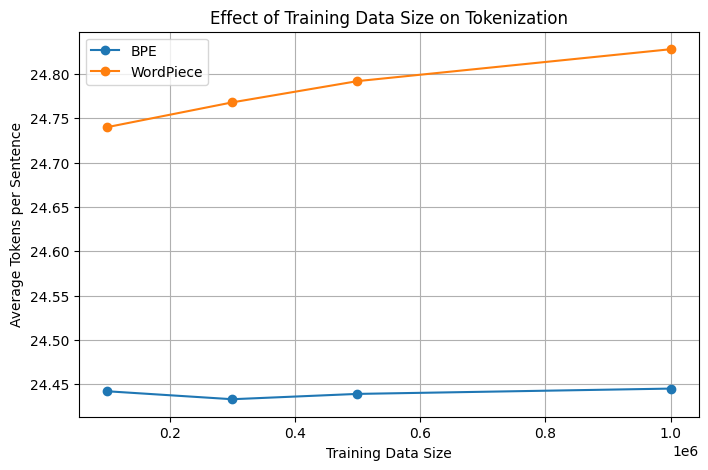

In [94]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

for tokenizer_name in ["BPE", "WordPiece"]:

    data = evaluation_df[
        evaluation_df["Tokenizer"] == tokenizer_name
    ]

    plt.plot(
        data["Training Size"],
        data["Dev Avg Tokens"],
        marker="o",
        label=tokenizer_name
    )

plt.xlabel("Training Data Size")
plt.ylabel("Average Tokens per Sentence")
plt.title(
    "Effect of Training Data Size on Tokenization"
)

plt.legend()
plt.grid(True)
plt.show()

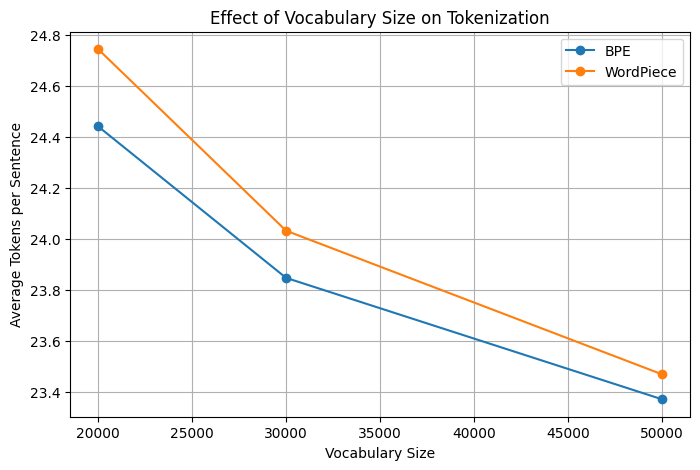

In [95]:
plt.figure(figsize=(8, 5))

for tokenizer_name in ["BPE", "WordPiece"]:

    data = vocab_comparison[
        vocab_comparison["Tokenizer"] == tokenizer_name
    ]

    plt.plot(
        data["Vocabulary Size"],
        data["Average Tokens"],
        marker="o",
        label=tokenizer_name
    )

plt.xlabel("Vocabulary Size")
plt.ylabel("Average Tokens per Sentence")
plt.title(
    "Effect of Vocabulary Size on Tokenization"
)

plt.legend()
plt.grid(True)
plt.show()

In [96]:
training_size_comparison.to_csv(
    "training_size_comparison.csv",
    index=False
)

vocab_comparison.to_csv(
    "vocabulary_size_comparison.csv",
    index=False
)

evaluation_df.to_csv(
    "dev_test_evaluation.csv",
    index=False
)

bpe_vocab_results_df.to_csv(
    "bpe_vocabulary_results.csv",
    index=False
)

wordpiece_vocab_results_df.to_csv(
    "wordpiece_vocabulary_results.csv",
    index=False
)

print("All results saved successfully.")

All results saved successfully.


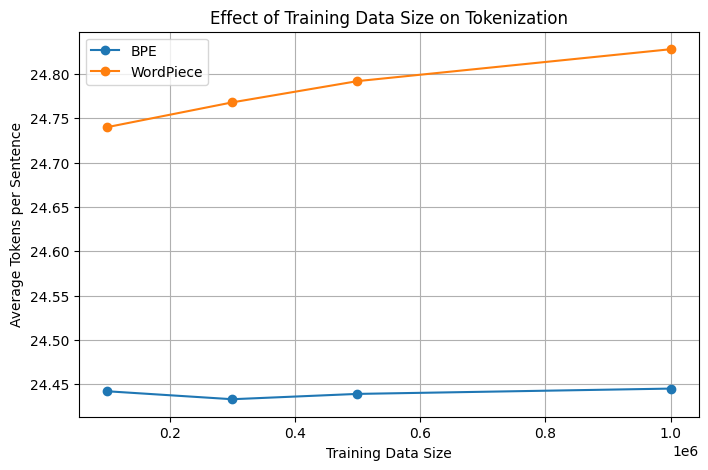

In [97]:
plt.figure(figsize=(8, 5))

for tokenizer_name in ["BPE", "WordPiece"]:

    data = evaluation_df[
        evaluation_df["Tokenizer"] == tokenizer_name
    ]

    plt.plot(
        data["Training Size"],
        data["Dev Avg Tokens"],
        marker="o",
        label=tokenizer_name
    )

plt.xlabel("Training Data Size")
plt.ylabel("Average Tokens per Sentence")
plt.title(
    "Effect of Training Data Size on Tokenization"
)

plt.legend()
plt.grid(True)

plt.savefig(
    "training_size_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

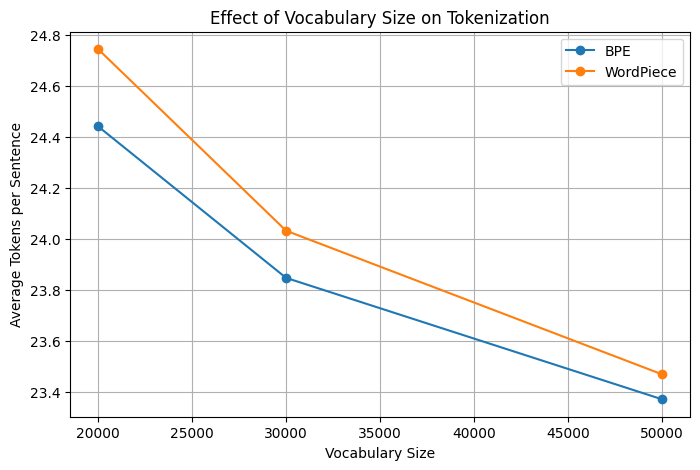

In [98]:
plt.figure(figsize=(8, 5))

for tokenizer_name in ["BPE", "WordPiece"]:

    data = vocab_comparison[
        vocab_comparison["Tokenizer"] == tokenizer_name
    ]

    plt.plot(
        data["Vocabulary Size"],
        data["Average Tokens"],
        marker="o",
        label=tokenizer_name
    )

plt.xlabel("Vocabulary Size")
plt.ylabel("Average Tokens per Sentence")
plt.title(
    "Effect of Vocabulary Size on Tokenization"
)

plt.legend()
plt.grid(True)

plt.savefig(
    "vocabulary_size_impact.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()